# BeanLeaf Doctor

End-to-end image classification for the African Leadership University machine-learning pipeline assignment.

The photographs come from the Makerere AI Lab iBean dataset, collected in Ugandan fields with the National Crops Resources Research Institute. Each image is one bean leaf and belongs to one of three classes:

- `angular_leaf_spot`
- `bean_rust`
- `healthy`

This notebook acquires the images, preprocesses them, trains a regularized transfer-learning model, and evaluates it with accuracy, loss, precision, recall, F1, and AUC. The saved network is the custom pretrained model that the API later fine-tunes.


In [1]:
import json
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src.acquire import dataset_ready, download_beans, extract_local_zips
from src.config import FEATURE_PATH, MODEL_PATH, PRETRAINED_PATH, TEST_DIR, TRAIN_DIR, VAL_DIR
from src.model import build_model, train_model, tune_learning_rate
from src.prediction import predict_image
from src.preprocessing import (
    CLASS_NAMES,
    count_images,
    feature_stories,
    load_rgb,
    save_feature_summary,
    to_model_array,
)

np.random.seed(42)
print("Project root:", ROOT)


Project root: C:\Users\EVOTECH\Downloads\Summative pipeline


## 1. Data acquisition

The original Google Cloud zip links for iBean now return HTTP 403. This project uses the public Hugging Face mirror, `AI-Lab-Makerere/beans`, which contains the same 1,295 labelled field photos. Images are saved under `data/train`, `data/validation`, and `data/test`, with one folder per class.


In [2]:
if dataset_ready():
    download_report = "Dataset already on disk. Skipping the download."
elif extract_local_zips():
    download_report = "Extracted the Hugging Face iBean zip archives into data/."
else:
    download_report = download_beans()

counts = {
    "train": count_images(TRAIN_DIR),
    "validation": count_images(VAL_DIR),
    "test": count_images(TEST_DIR),
}
print(download_report)
counts


Dataset already on disk. Skipping the download.


{'train': {'angular_leaf_spot': 345,
  'bean_rust': 348,
  'healthy': 341,
  'total': 1034},
 'validation': {'angular_leaf_spot': 44,
  'bean_rust': 45,
  'healthy': 44,
  'total': 133},
 'test': {'angular_leaf_spot': 43,
  'bean_rust': 43,
  'healthy': 42,
  'total': 128}}

## 2. Data processing

Field photos are not the same size, and phone cameras store a rotation flag. Every image goes through the same steps before it reaches the network:

1. Apply the EXIF orientation and convert to RGB, so a greyscale or rotated phone photo cannot change the channel order.
2. Resize to 224 by 224 pixels. MobileNetV2 was pretrained at this size.
3. Scale each pixel with `x / 127.5 - 1`, which maps 0–255 onto the `[-1, 1]` range the pretrained backbone expects.
4. During training only, randomly flip, rotate, and zoom. The validation and test photos are never augmented.

The same function used here is the one the API uses at prediction time, so a leaf is prepared identically offline and in production.


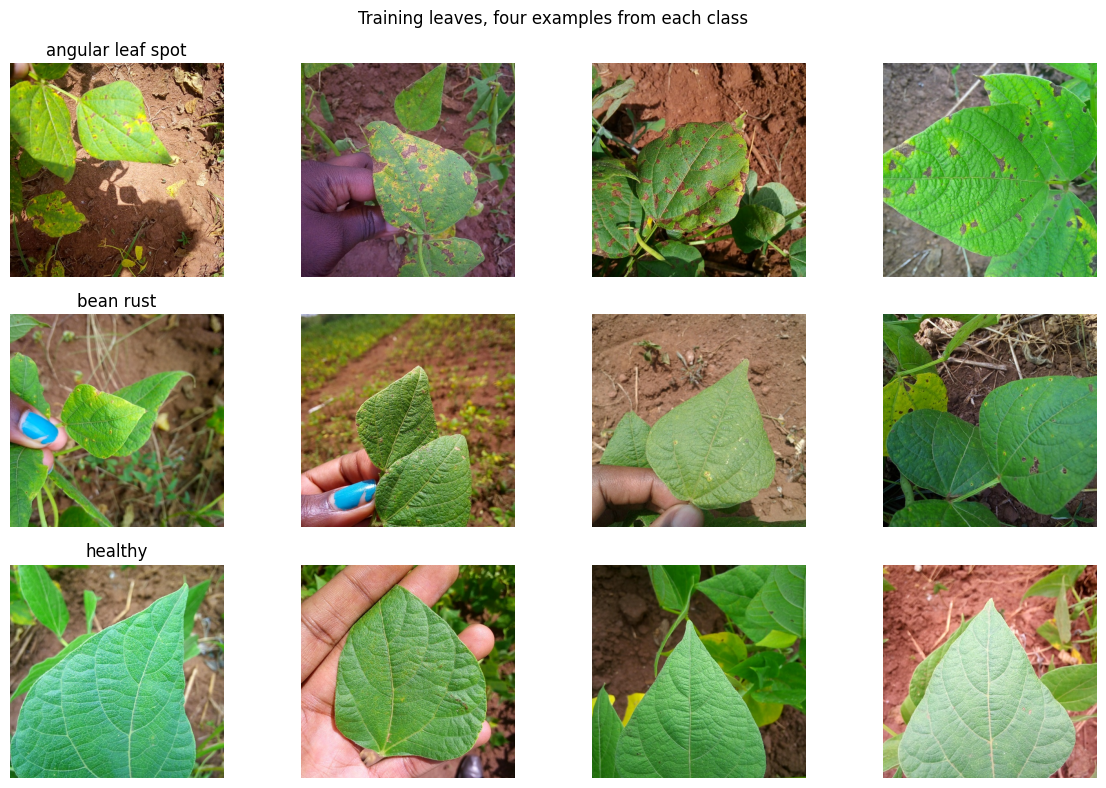

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for row, class_name in enumerate(CLASS_NAMES):
    paths = sorted((TRAIN_DIR / class_name).glob("*.jpg"))[:4]
    for col, path in enumerate(paths):
        axes[row, col].imshow(load_rgb(path))
        axes[row, col].set_title(class_name.replace("_", " ") if col == 0 else "")
        axes[row, col].axis("off")
fig.suptitle("Training leaves, four examples from each class")
fig.tight_layout()
plt.show()


Original size: (500, 500)
Model input shape: (224, 224, 3)
Scaled min/max: -1.0 1.0
Helper matches the manual scaling: False


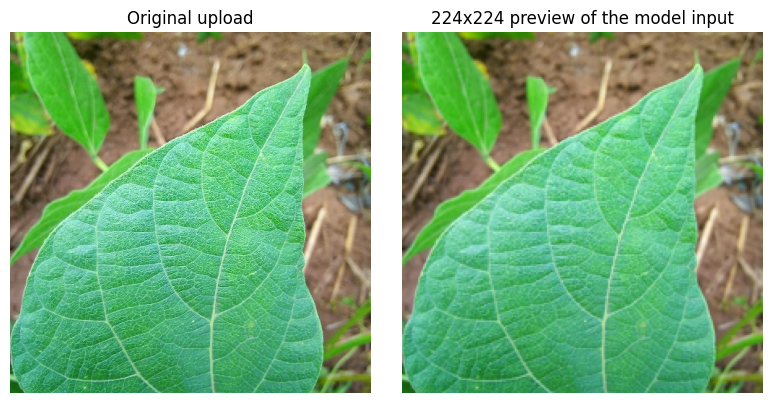

In [4]:
sample_path = next((TRAIN_DIR / "healthy").glob("*.jpg"))
original = load_rgb(sample_path)
resized = original.resize((224, 224))
pixels = np.asarray(resized, dtype="float32")
scaled = pixels / 127.5 - 1.0
model_ready = to_model_array(original)

print("Original size:", original.size)
print("Model input shape:", model_ready.shape)
print("Scaled min/max:", round(float(scaled.min()), 3), round(float(scaled.max()), 3))
print("Helper matches the manual scaling:", bool(np.allclose(scaled, model_ready)))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original)
axes[0].set_title("Original upload")
axes[1].imshow((scaled + 1) / 2)
axes[1].set_title("224x224 preview of the model input")
for axis in axes:
    axis.axis("off")
fig.tight_layout()
plt.show()


## 3. What the photos are showing

A convolutional network is accurate, but it is a poor explanation by itself. These four measurements are computed from the pixels so a person can see why the classes differ:

- **Green dominance** is the share of the average colour that is green. Chlorophyll keeps a healthy leaf greener.
- **Rust index** is red divided by green. Bean rust adds reddish-brown pustules.
- **Lesion contrast** is the spread of brightness. Angular leaf spot punches dark patches into the blade.
- **Edge density** is the average change between neighbouring pixels. Spots and pustules add edges.

Brightness is calculated as well, so a difference that is only caused by a darker photograph can be spotted.


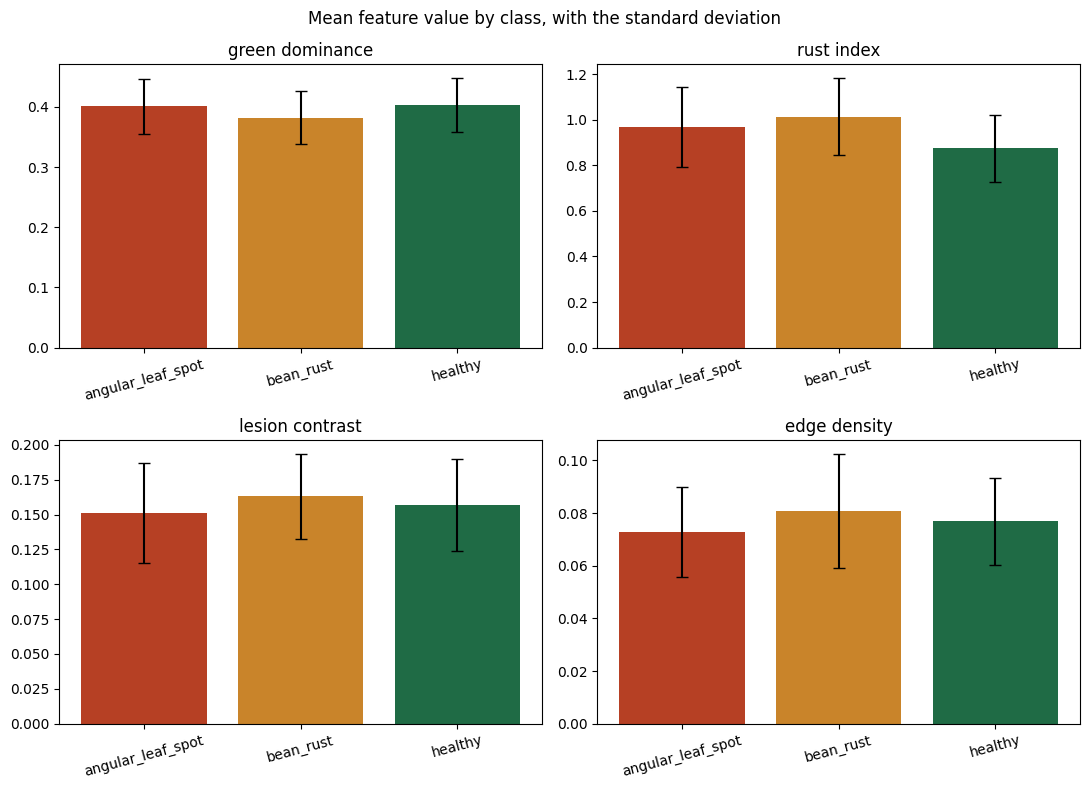

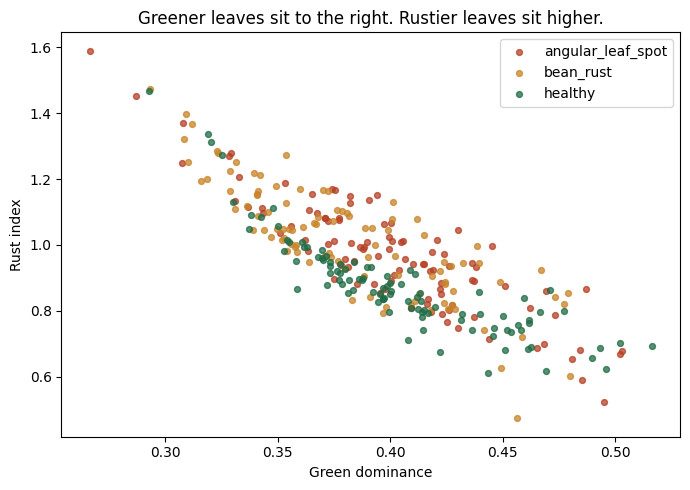

**Green share of the leaf.** Healthy has the strongest green share (0.404). Chlorophyll reflects green light, so leaves that are still intact score higher. Lesions replace that tissue and pull the green share down.

**Red relative to green.** Bean rust scores the highest rust index (1.013). Bean rust grows reddish-brown pustules, which add red without adding green. Angular leaf spot is browner and duller, while a healthy leaf stays greener and keeps this ratio lower.

**How uneven the brightness is.** Lesion contrast does not separate the classes. Bean rust is only slightly higher at 0.163, and the other two classes sit within a few thousandths. Dark spots do not become a stable contrast gap in these field photos. The colour ratios above are the useful clue.

**Edges from spots and pustules.** Bean rust shows the most edge density (0.081). Spots, halos, and pustules create small brightness changes that a clean leaf does not. Average brightness only varies by 0.060 across the three classes, so these colour and texture gaps are not just an exposure artefact.

In [5]:
summary = save_feature_summary(TRAIN_DIR, FEATURE_PATH, per_class=100)
stories = feature_stories(summary)
feature_names = ["green_dominance", "rust_index", "lesion_contrast", "edge_density"]
colours = ["#b64024", "#c9842a", "#1f6b45"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, feature_name in zip(axes.ravel(), feature_names):
    means = [summary["features"][feature_name][name]["mean"] for name in CLASS_NAMES]
    spread = [summary["features"][feature_name][name]["std"] for name in CLASS_NAMES]
    axis.bar(CLASS_NAMES, means, yerr=spread, color=colours, capsize=4)
    axis.set_title(feature_name.replace("_", " "))
    axis.tick_params(axis="x", labelrotation=15)
fig.suptitle("Mean feature value by class, with the standard deviation")
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(7, 5))
for class_name, colour in zip(CLASS_NAMES, colours):
    xs = summary["features"]["green_dominance"][class_name]["values"]
    ys = summary["features"]["rust_index"][class_name]["values"]
    axis.scatter(xs, ys, s=18, alpha=0.75, label=class_name, color=colour)
axis.set_xlabel("Green dominance")
axis.set_ylabel("Rust index")
axis.set_title("Greener leaves sit to the right. Rustier leaves sit higher.")
axis.legend()
fig.tight_layout()
plt.show()

for story in stories:
    display(Markdown(f"**{story['title']}.** {story['text']}"))


## 4. Model creation

The classifier is a custom head on MobileNetV2 pretrained with ImageNet. The backbone stays frozen for the first training run, and Batch Normalisation stays in inference mode so the leaf photos do not overwrite the pretrained statistics.

Optimisation choices:

- **Pretrained model:** ImageNet MobileNetV2, with a new 128-unit dense layer and a 3-class softmax.
- **Regularisation:** dropout of 0.4 and 0.2, plus L2 on the dense kernel.
- **Optimiser:** Adam. Two learning rates are scored on a short run, and the lower validation loss is kept.
- **Early stopping:** stop after three epochs without a better validation loss and restore the best weights.
- **Learning-rate schedule:** reduce the learning rate by half when validation loss stalls.
- **Augmentation:** horizontal flip, small rotation, and zoom, applied only to training batches.


In [6]:
tuning = tune_learning_rate(TRAIN_DIR, VAL_DIR)
print(json.dumps(tuning, indent=2))
selected_lr = tuning["selected_learning_rate"]

preview = build_model(learning_rate=selected_lr)
preview.summary()
del preview


Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


6/6 - 18s - 3s/step - accuracy: 0.4896 - auc: 0.6515 - loss: 1.2141 - precision: 0.5309 - recall: 0.4479 - val_accuracy: 0.7500 - val_auc: 0.9065 - val_loss: 0.6394 - val_precision: 0.8095 - val_recall: 0.7083


Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


6/6 - 20s - 3s/step - accuracy: 0.4167 - auc: 0.6127 - loss: 1.2665 - precision: 0.4507 - recall: 0.3333 - val_accuracy: 0.8958 - val_auc: 0.9760 - val_loss: 0.4807 - val_precision: 0.9524 - val_recall: 0.8333


... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pooled_features                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_pool (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_embedding (Dense)       │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_embedding (Dropout)     │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
metrics = train_model(
    train_dir=TRAIN_DIR,
    val_dir=VAL_DIR,
    test_dir=TEST_DIR,
    learning_rate=selected_lr,
    tune=False,
)
print("Epochs completed:", metrics["epochs_ran"])
print("Selected learning rate:", metrics["learning_rate"])


Found 1034 files belonging to 3 classes.


Found 133 files belonging to 3 classes.


Epoch 1/6


65/65 - 46s - 700ms/step - accuracy: 0.6576 - auc: 0.8411 - loss: 0.7928 - precision: 0.6887 - recall: 0.6141 - val_accuracy: 0.7820 - val_auc: 0.9277 - val_loss: 0.5356 - val_precision: 0.8080 - val_recall: 0.7594 - learning_rate: 5.0000e-04


Epoch 2/6


65/65 - 39s - 604ms/step - accuracy: 0.8037 - auc: 0.9360 - loss: 0.5061 - precision: 0.8232 - recall: 0.7834 - val_accuracy: 0.8421 - val_auc: 0.9592 - val_loss: 0.4061 - val_precision: 0.8583 - val_recall: 0.8195 - learning_rate: 5.0000e-04


... (6 outputs left out)

Epoch 6/6


65/65 - 70s - 1s/step - accuracy: 0.8772 - auc: 0.9727 - loss: 0.3316 - precision: 0.8832 - recall: 0.8704 - val_accuracy: 0.8797 - val_auc: 0.9804 - val_loss: 0.2937 - val_precision: 0.8864 - val_recall: 0.8797 - learning_rate: 5.0000e-04


Found 128 files belonging to 3 classes.


Epochs completed: 6
Selected learning rate: 0.0005


## 5. Model test

The test folder is never used for training or for the learning-rate search. Loss is the categorical cross-entropy of the predicted probabilities. Precision, recall, and F1 are macro averages, so each disease counts equally. AUC is the macro one-vs-rest score.


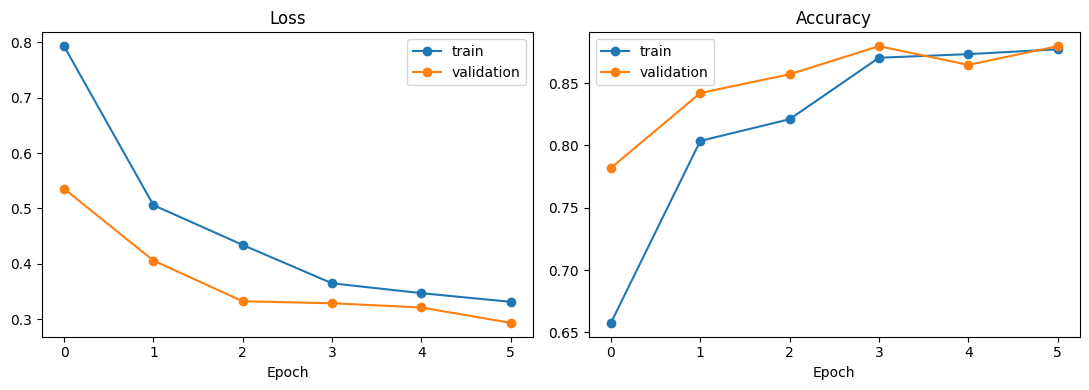

{
  "accuracy": 0.90625,
  "loss": 0.26453607724321504,
  "precision": 0.9106060606060605,
  "recall": 0.9067921742340347,
  "f1": 0.9042285655025797,
  "auc": 0.9761720191952751
}


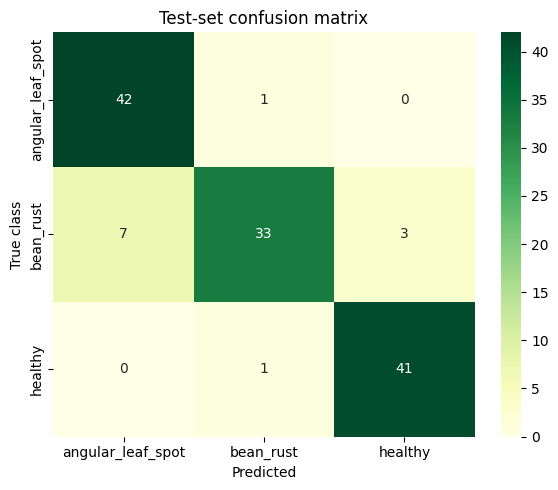

angular_leaf_spot    precision 0.857  recall 0.977  f1 0.913  support 43
bean_rust            precision 0.943  recall 0.767  f1 0.846  support 43
healthy              precision 0.932  recall 0.976  f1 0.953  support 42


In [8]:
history = metrics["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["loss"], marker="o", label="train")
axes[0].plot(history["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history["accuracy"], marker="o", label="train")
axes[1].plot(history["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
fig.tight_layout()
plt.show()

score_names = ["accuracy", "loss", "precision", "recall", "f1", "auc"]
scores = {name: metrics[name] for name in score_names}
print(json.dumps(scores, indent=2))

fig, axis = plt.subplots(figsize=(6, 5))
sns.heatmap(
    np.array(metrics["confusion_matrix"]),
    annot=True,
    fmt="d",
    cmap="YlGn",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=axis,
)
axis.set_xlabel("Predicted")
axis.set_ylabel("True class")
axis.set_title("Test-set confusion matrix")
fig.tight_layout()
plt.show()

report = metrics["classification_report"]
for class_name in CLASS_NAMES:
    row = report[class_name]
    print(
        f"{class_name:20} precision {row['precision']:.3f}  "
        f"recall {row['recall']:.3f}  f1 {row['f1-score']:.3f}  support {int(row['support'])}"
    )


## 6. Prediction function

`predict_image` is the function the API calls. It loads the saved `.keras` file, preprocesses one photograph, and returns the class, the three probabilities, and the colour/texture features. The six photos below are taken from the test folders, so the folder name is the true label.


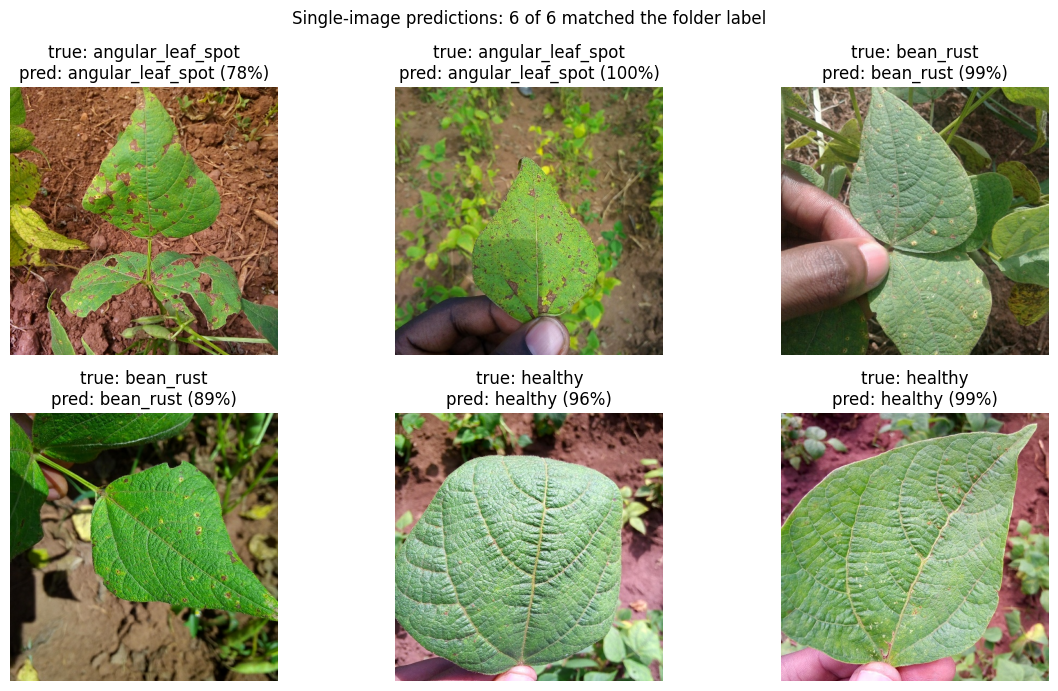

6/6 correct


In [9]:
picks = []
for class_name in CLASS_NAMES:
    picks.extend(sorted((TEST_DIR / class_name).glob("*.jpg"))[:2])

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
correct = 0
for axis, path in zip(axes.ravel(), picks):
    truth = path.parent.name
    result = predict_image(path, MODEL_PATH)
    matched = result["label"] == truth
    correct += int(matched)
    axis.imshow(load_rgb(path))
    axis.set_title(f"true: {truth}\npred: {result['label']} ({result['confidence']:.0%})")
    axis.axis("off")
fig.suptitle(f"Single-image predictions: {correct} of {len(picks)} matched the folder label")
fig.tight_layout()
plt.show()
print(f"{correct}/{len(picks)} correct")


## 7. Retraining from this custom model

The first training run writes two copies:

- `models/bean_leaf_model.keras` is the active model. Retraining updates it.
- `models/bean_leaf_pretrained.keras` stays as the original custom model.
- `models/bean_leaf_model.h5` is the same active network in HDF5 format.

The API saves newly uploaded leaves, records them in SQLite, and preprocesses them with the same RGB, resize, and scaling steps. A button starts fine-tuning. A second trigger starts it automatically once 15 new labelled images are waiting. Fine-tuning loads the active custom model, unfreezes the top of the backbone at a learning rate of `1e-4`, and mixes the new leaves with a replay sample so the earlier classes are not forgotten. The held-out test set is scored again after every retrain.


In [10]:
print("Active model:", MODEL_PATH, MODEL_PATH.exists())
print("Custom pretrained copy:", PRETRAINED_PATH, PRETRAINED_PATH.exists())
print("Test images held out:", count_images(TEST_DIR))
print(json.dumps(metrics["optimization"], indent=2))


Active model: C:\Users\EVOTECH\Downloads\Summative pipeline\models\bean_leaf_model.keras True
Custom pretrained copy: C:\Users\EVOTECH\Downloads\Summative pipeline\models\bean_leaf_pretrained.keras True
Test images held out: {'angular_leaf_spot': 43, 'bean_rust': 43, 'healthy': 42, 'total': 128}
{
  "backbone": "MobileNetV2 ImageNet weights, frozen",
  "optimizer": "Adam",
  "regularization": "Dropout 0.4 / 0.2 and L2 on the dense layer",
  "early_stopping": "patience 3, restore best weights",
  "lr_schedule": "ReduceLROnPlateau",
  "augmentation": "horizontal flip, rotation, zoom"
}
